# 01 — Data preparation and EDA

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data/processed').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'processed'
labels = ['toxic','severe_toxic','obscene','threat','insult','identity_hate']
master = pd.read_csv(DATA/'unified_master.csv')
jigsaw = pd.read_csv(DATA/'jigsaw_cleaned.csv')
sms = pd.read_csv(DATA/'sms_cleaned.csv')
print('Jigsaw rows:', len(jigsaw), '| SMS rows:', len(sms), '| merged rows:', len(master))
display(master.head(8))

/var/folders/44/fywnm5sj335fdzvrq6s4_m3c0000gn/T/ipykernel_55404/1640696271.py:10: DtypeWarning: Columns (9: spam_label) have mixed types. Specify dtype option on import or set low_memory=False.
  master = pd.read_csv(DATA/'unified_master.csv')


Jigsaw rows: 159374 | SMS rows: 5160 | merged rows: 164534


,id,text,source,toxic,severe_toxic,obscene,threat,insult,identity_hate,spam_label,spam
0,0000997932d777bf,Explanation Why the edits made under my userna...,jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
3,0001b41b1c6bb37e,""" More I can't make any real suggestions on im...",jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
5,00025465d4725e87,""" Congratulations from me as well, use the too...",jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,jigsaw,1.0,1.0,1.0,0.0,1.0,0.0,NaN,NaN
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,jigsaw,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN


## Why the merge keeps labels separate
Jigsaw is multi-label toxicity classification; SMS is binary ham/spam classification. 

,rows
source,
jigsaw,159374
sms,5160


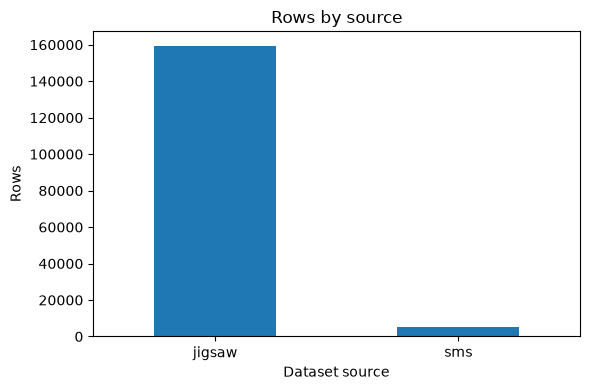

In [2]:
display(master.groupby('source').size().rename('rows').to_frame())
fig, ax = plt.subplots(figsize=(6,4))
master.groupby('source').size().plot(kind='bar', ax=ax)
ax.set_title('Rows by source'); ax.set_xlabel('Dataset source'); ax.set_ylabel('Rows'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

,positive_rows
toxic,15262
obscene,8429
insult,7858
severe_toxic,1592
identity_hate,1400
threat,475


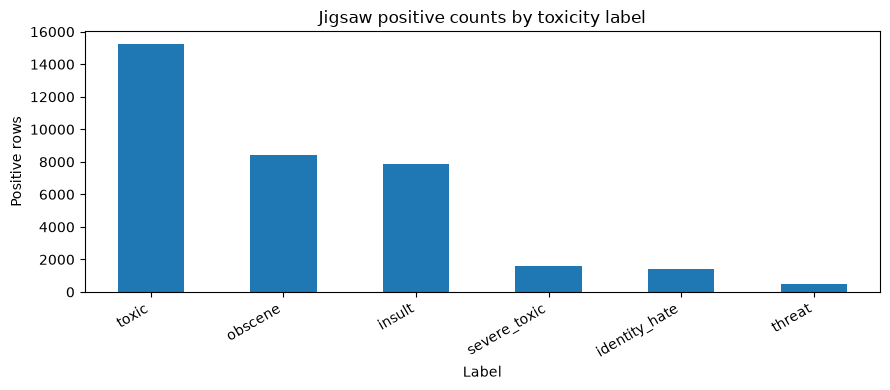

In [3]:
toxicity_counts = jigsaw[labels].sum().sort_values(ascending=False)
display(toxicity_counts.rename('positive_rows').to_frame())
fig, ax = plt.subplots(figsize=(9,4))
toxicity_counts.plot(kind='bar', ax=ax)
ax.set_title('Jigsaw positive counts by toxicity label'); ax.set_xlabel('Label'); ax.set_ylabel('Positive rows'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

,rows
spam_label,
ham,4518
spam,642


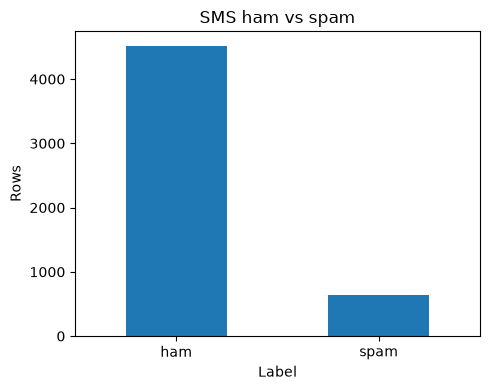

In [4]:
spam_counts = sms['spam_label'].value_counts()
display(spam_counts.rename('rows').to_frame())
fig, ax = plt.subplots(figsize=(5,4))
spam_counts.plot(kind='bar', ax=ax)
ax.set_title('SMS ham vs spam'); ax.set_xlabel('Label'); ax.set_ylabel('Rows'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
jigsaw,159374.0,390.9,586.5,6.0,94.0,203.0,432.0,5000.0
sms,5160.0,79.1,58.2,2.0,36.0,61.0,118.0,910.0


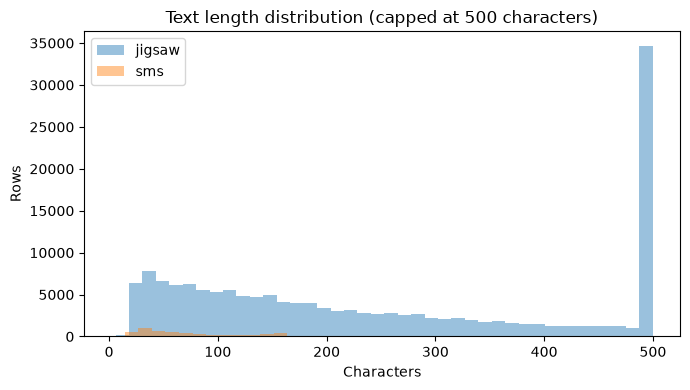

In [5]:
master['text_length'] = master['text'].fillna('').str.len()
display(master.groupby('source')['text_length'].describe().round(1))
fig, ax = plt.subplots(figsize=(7,4))
for source, group in master.groupby('source'):
    group['text_length'].clip(upper=500).plot(kind='hist', bins=40, alpha=.45, ax=ax, label=source)
ax.set_title('Text length distribution (capped at 500 characters)'); ax.set_xlabel('Characters'); ax.set_ylabel('Rows'); ax.legend(); plt.tight_layout(); plt.show()